# 02 - Hydrology EDA: how do these rivers actually behave?

**In plain words.** Notebook 01 proved the data can be trusted. This notebook looks at the *rivers themselves*: how fast they react, how skewed the flows are, how long the river "remembers" yesterday, how long a flood wave takes to travel downstream, and how hard it is to beat the laziest possible forecast ("tomorrow = today"). Every section ends in a **decision** for the modelling notebooks, so the EDA visibly drives the design.

**Rules this notebook follows (from CLAUDE.md).**
- Rain always means `precip_local` (rain moved to the local clock in notebook 01). The raw `precipitation` column is never used.
- Anything that is *estimated* (flood thresholds, lags, scalers) uses **training years only** (2011-10 to 2016-09).
- The **test year (2018) is never looked at**. Persistence skill is measured on the validation year only.
- Missing flow stays missing. Nothing is interpolated.
- Results are per station, never one pooled number.

**Needs:** `processed/waterbench_ts_clean.parquet` and `processed/static_attributes.csv` from notebook 01. **Produces:** figures 08-18 in `figures/`, plus `processed/flood_thresholds_train.csv`, `flood_events_trainval.csv`, `upstream_lags.csv`, `station_groups.csv`, `persistence_skill_val.csv` and `splits.json`.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 170)
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C", "#8172B3"
SEED = 42
np.random.seed(SEED)

ROOT = Path(".")
PROC = ROOT / "processed"; FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True); PROC.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

def pair_corr(a, b, min_n=500):
    """Pearson correlation using only the hours where both series have a value."""
    m = ~(np.isnan(a) | np.isnan(b))
    if m.sum() < min_n:
        return np.nan
    a, b = a[m], b[m]
    sa, sb = a.std(), b.std()
    if sa == 0 or sb == 0:
        return np.nan
    return float(np.mean((a - a.mean()) * (b - b.mean())) / (sa * sb))

def lag_corr(x, y, k, min_n=500):
    """corr( x(t-k), y(t) ): does y follow x by k hours?"""
    if k == 0:
        return pair_corr(x, y, min_n)
    return pair_corr(x[:-k], y[k:], min_n)

## 0. Load the cleaned data as a station x hour grid

**In plain words.** All 125 gauges share the exact same hourly clock, so we can store flow and rain as two tables of shape *125 stations x 61,368 hours*. That makes every later calculation fast and keeps stations lined up by time. The long data from notebook 01 is reshaped (and checked) rather than re-read from the raw CSVs.

`Qm` is flow in m3/s with the 15 flagged one-hour spikes blanked out. Flat-line hours are kept (they can be genuine low flow). Missing flow stays `NaN`.

In [2]:
N = 61_368
df = pd.read_parquet(PROC / "waterbench_ts_clean.parquet")
static = pd.read_csv(PROC / "static_attributes.csv", dtype={"station": str}).set_index("station")
rel = pd.read_csv(ROOT / "catchment_relationship.csv")
rel["station_id"] = rel["station_id"].astype(int).astype(str)
rel["upstream_id"] = rel["upstream_id"].astype(int).astype(str)

stations = list(df["station"].astype(str).iloc[::N])
assert len(df) == len(stations) * N, "every station must have exactly 61,368 rows"
assert (df["station"].astype(str).to_numpy().reshape(len(stations), N) == np.array(stations)[:, None]).all()
assert (df["datetime"].to_numpy().reshape(len(stations), N) == df["datetime"].to_numpy()[:N][None, :]).all(), "stations are not on one shared clock"

idx = {s: i for i, s in enumerate(stations)}
time = pd.DatetimeIndex(df["datetime"].iloc[:N])
split = df["split"].astype(str).iloc[:N].to_numpy()
Q = df["q_cms"].to_numpy().reshape(len(stations), N)
Qm = np.where(df["flag_spike"].to_numpy().reshape(len(stations), N), np.nan, Q)
P = df["precip_local"].to_numpy().reshape(len(stations), N)
static = static.loc[stations]
area, tt = static["area"].to_numpy(), static["travel_time"].to_numpy()

ntr, nva, nte = [int((split == s).sum()) for s in ("train", "val", "test")]
assert (split[:ntr] == "train").all() and (split[ntr:ntr + nva] == "val").all() and (split[ntr + nva:] == "test").all()
size_group = pd.qcut(static["area"], 3, labels=["small", "medium", "large"])
GROUP_COL = {"small": ORANGE, "medium": BLUE, "large": GREEN}

print(f"{len(stations)} stations x {N:,} hours | train {ntr:,} h ({time[0].date()} to {time[ntr-1].date()}) | "
      f"val {nva:,} h | test {nte:,} h (not used here)")
print("size groups (terciles of catchment area):")
print(static.groupby(size_group, observed=True)["area"].agg(["count", "min", "median", "max"]).round(0).to_string())

125 stations x 61,368 hours | train 43,848 h (2011-10-01 to 2016-09-30) | val 8,760 h | test 8,760 h (not used here)
size groups (terciles of catchment area):
        count     min   median      max
area                                   
small      42     6.0    536.0   1064.0
medium     41  1080.0   1918.0   3989.0
large      42  4013.0  10168.0  36453.0


## 1. What do these rivers look like?

**In plain words.** Four gauges, picked to span the size range, over one full water year (Oct 2014 - Sep 2015). Grey bars hang from the top: that is rain. The blue line is the river. A small creek jumps within hours of a storm and falls back just as fast. A large river rises slowly, stays high for days, and barely notices a single storm. One model has to cope with all of this, which is why catchment size and concentration time will be model inputs.

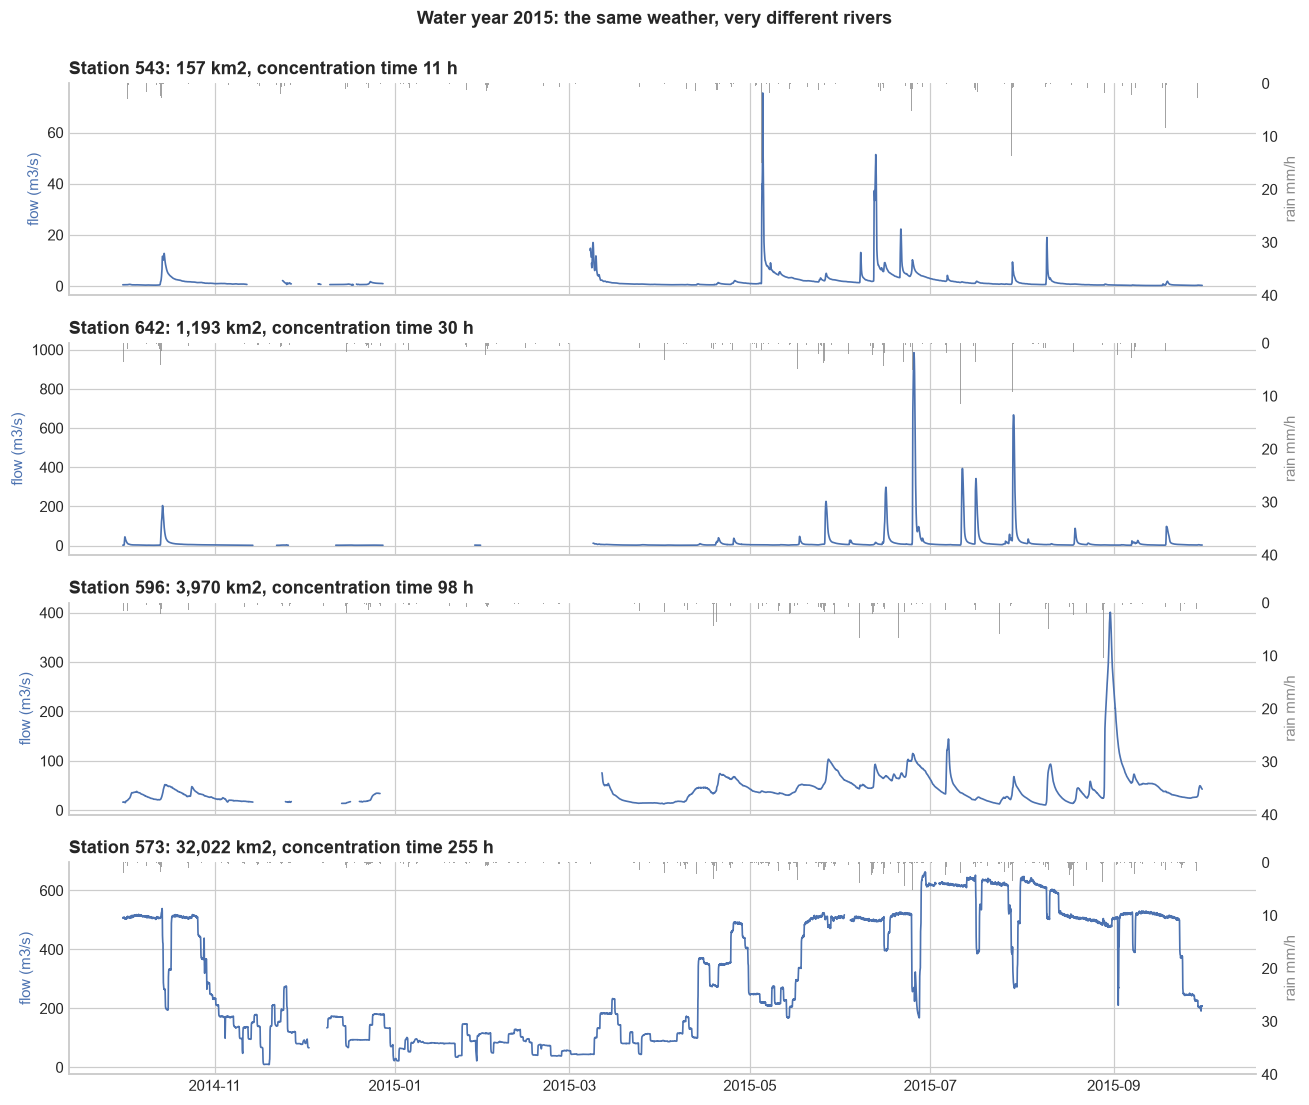

peak / median flow in this water year: {'543': np.float64(79.0), '642': np.float64(247.1), '596': np.float64(11.2), '573': np.float64(2.7)}


In [3]:
ok = static["flow_missing_pct"] < 20
pick = [(static.loc[ok, "area"] - static.loc[ok, "area"].quantile(q)).abs().idxmin() for q in (0.05, 0.35, 0.65, 0.95)]
WY = 2015
wm = (time >= f"{WY-1}-10-01") & (time < f"{WY}-10-01")

fig, axes = plt.subplots(len(pick), 1, figsize=(12, 10), sharex=True)
for ax, s in zip(axes, pick):
    i = idx[s]
    ax.plot(time[wm], Qm[i, wm], color=BLUE, lw=1.1)
    ax.set_ylabel("flow (m3/s)", color=BLUE)
    ax.set_title(f"Station {s}: {area[i]:,.0f} km2, concentration time {tt[i]:.0f} h", loc="left")
    ax2 = ax.twinx()
    ax2.bar(time[wm], np.nan_to_num(P[i, wm]), width=1 / 24, color=GREY, alpha=0.8)
    ax2.set_ylim(40, 0); ax2.grid(False); ax2.set_ylabel("rain mm/h", color=GREY)
fig.suptitle(f"Water year {WY}: the same weather, very different rivers", fontweight="bold", y=1.0)
savefig("08_hydrographs_four_sizes.png")

peak_ratio = {s: np.nanmax(Qm[idx[s], wm]) / np.nanmedian(Qm[idx[s], wm]) for s in pick}
print("peak / median flow in this water year:", {s: round(v, 1) for s, v in peak_ratio.items()})

## 2. How skewed are the flows? (flow-duration curves)

**In plain words.** A *flow-duration curve* sorts every hour from highest flow to lowest. The far left is the rare floods, the long flat part on the right is everyday flow. Rivers spend most of their time low and only rarely roar. That is a problem for training: a model that minimises ordinary squared error learns the boring everyday flow very well and ignores the floods, which are exactly what we need. The right panel divides each river by its own median so you can compare shapes.

Then we test three ways of squashing the skew (square root, log, none) with the **skewness** statistic. Zero is symmetric; large positive is a long flood tail.

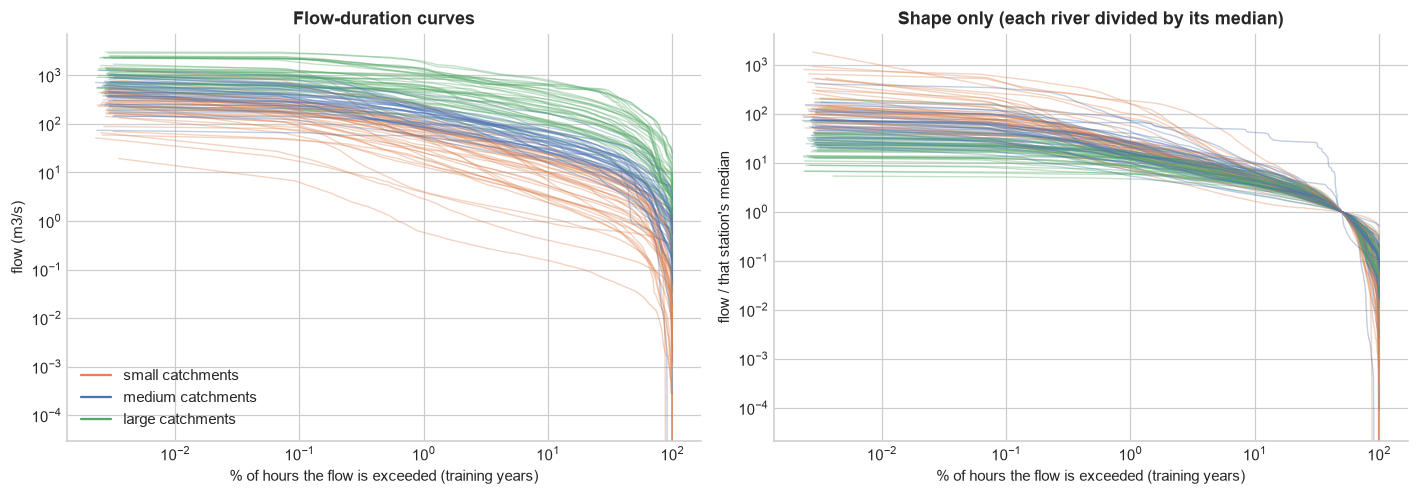

,skew_raw,skew_sqrt,skew_log,q99_over_q50
min,0.75,0.18,-0.74,4.69
25%,3.50,1.29,-0.17,11.93
50%,5.61,1.95,0.06,15.53
75%,9.15,2.94,0.33,22.66
max,27.46,7.98,2.37,183.62


Median skewness: raw 5.6 -> sqrt 1.9 -> log 0.1
The 99th-percentile flow is a median of 16x the median flow (range 5x to 184x).
Stations with any exactly-zero flow hours: 7 of 125


In [4]:
Qtr = Qm[:, :ntr]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for i, s in enumerate(stations):
    q = np.sort(Qtr[i][~np.isnan(Qtr[i])])[::-1]
    ex = np.arange(1, len(q) + 1) / len(q) * 100
    g = size_group.iloc[i]
    axes[0].plot(ex[::25], q[::25], color=GROUP_COL[g], alpha=0.35, lw=0.9)
    med = np.median(q)
    if med > 0:
        axes[1].plot(ex[::25], q[::25] / med, color=GROUP_COL[g], alpha=0.35, lw=0.9)
for ax in axes:
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("% of hours the flow is exceeded (training years)")
axes[0].set_ylabel("flow (m3/s)"); axes[1].set_ylabel("flow / that station's median")
axes[0].set_title("Flow-duration curves"); axes[1].set_title("Shape only (each river divided by its median)")
for g, c in GROUP_COL.items():
    axes[0].plot([], [], color=c, label=f"{g} catchments")
axes[0].legend()
savefig("09_flow_duration_curves.png")

rows = []
for i, s in enumerate(stations):
    q = Qtr[i][~np.isnan(Qtr[i])]
    eps = 0.01 * q.mean()
    rows.append((s, stats.skew(q), stats.skew(np.sqrt(q)), stats.skew(np.log(q + eps)), np.percentile(q, 99) / np.median(q), (q == 0).mean() * 100))
skew_tbl = pd.DataFrame(rows, columns=["station", "skew_raw", "skew_sqrt", "skew_log", "q99_over_q50", "pct_zero_flow"]).set_index("station")
display(skew_tbl[["skew_raw", "skew_sqrt", "skew_log", "q99_over_q50"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))
print(f"Median skewness: raw {skew_tbl.skew_raw.median():.1f} -> sqrt {skew_tbl.skew_sqrt.median():.1f} -> log {skew_tbl.skew_log.median():.1f}")
print(f"The 99th-percentile flow is a median of {skew_tbl.q99_over_q50.median():.0f}x the median flow (range {skew_tbl.q99_over_q50.min():.0f}x to {skew_tbl.q99_over_q50.max():.0f}x).")
print(f"Stations with any exactly-zero flow hours: {(skew_tbl.pct_zero_flow > 0).sum()} of {len(skew_tbl)}")

## 3. How flashy is each river?

**In plain words.** The *Richards-Baker flashiness index* adds up all the hour-to-hour jumps in flow and divides by the total flow. Near 0 means smooth and sluggish; larger means spiky. It is a single number that says how much warning a river gives, and it is the first thing a gate operator would want to know. We expect it to fall as catchments get larger.

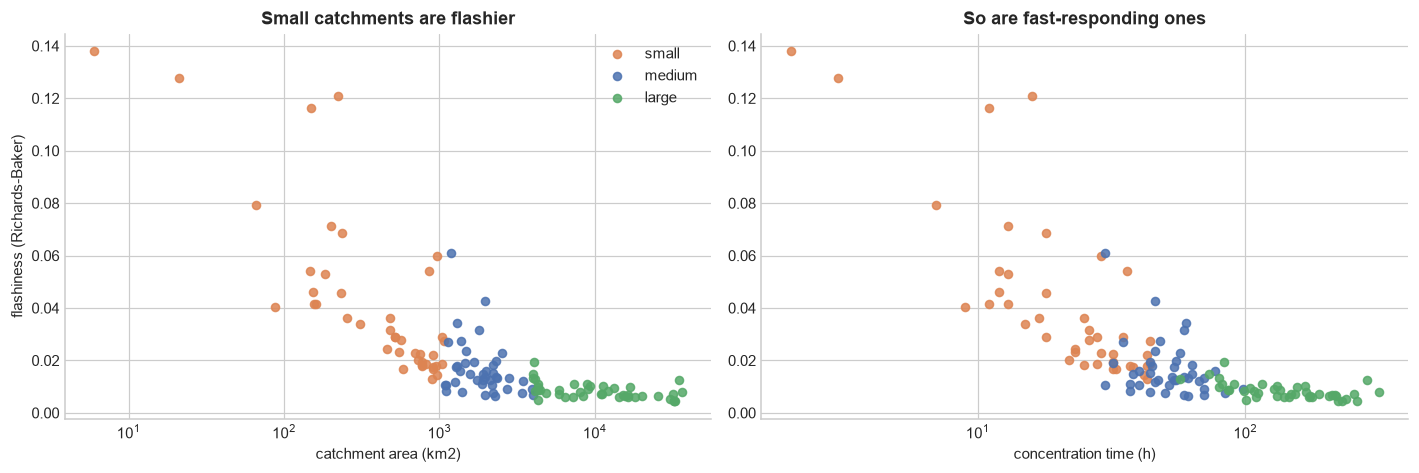

Spearman correlation of flashiness with: area -0.85 | concentration time -0.85 | slope +0.14
        count    min    50%    max
area                              
small    42.0  0.013  0.029  0.138
medium   41.0  0.006  0.014  0.061
large    42.0  0.004  0.008  0.019


In [5]:
def rb_index(q):
    a, b = q[:-1], q[1:]
    m = ~(np.isnan(a) | np.isnan(b))
    return np.abs(b[m] - a[m]).sum() / b[m].sum() if m.sum() > 500 else np.nan

rb = pd.Series([rb_index(Qtr[i]) for i in range(len(stations))], index=stations, name="rb_flashiness")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for g, c in GROUP_COL.items():
    m = (size_group == g).to_numpy()
    axes[0].scatter(area[m], rb[m], color=c, s=28, alpha=0.85, label=g)
    axes[1].scatter(tt[m], rb[m], color=c, s=28, alpha=0.85, label=g)
axes[0].set_xscale("log"); axes[0].set_xlabel("catchment area (km2)"); axes[0].set_ylabel("flashiness (Richards-Baker)")
axes[1].set_xscale("log"); axes[1].set_xlabel("concentration time (h)")
axes[0].legend(); axes[0].set_title("Small catchments are flashier"); axes[1].set_title("So are fast-responding ones")
savefig("10_flashiness.png")

rho_area = stats.spearmanr(area, rb, nan_policy="omit")[0]
rho_tt = stats.spearmanr(tt, rb, nan_policy="omit")[0]
rho_slope = stats.spearmanr(static["slope"], rb, nan_policy="omit")[0]
print(f"Spearman correlation of flashiness with: area {rho_area:+.2f} | concentration time {rho_tt:+.2f} | slope {rho_slope:+.2f}")
print(rb.groupby(size_group, observed=True).describe()[["count", "min", "50%", "max"]].round(3).to_string())

## 4. Seasons and time of day

**In plain words.** Two questions. (a) *When in the year is the river high?* We look at the data rather than assume. (b) *When in the day does it rain?* In the US Midwest, warm-season rain tends to come from organised storm systems that peak at night and early morning, not from afternoon showers. The daily rain cycle is only readable because we fixed the clock in notebook 01: on the raw UTC clock the peak would sit 5 hours off.

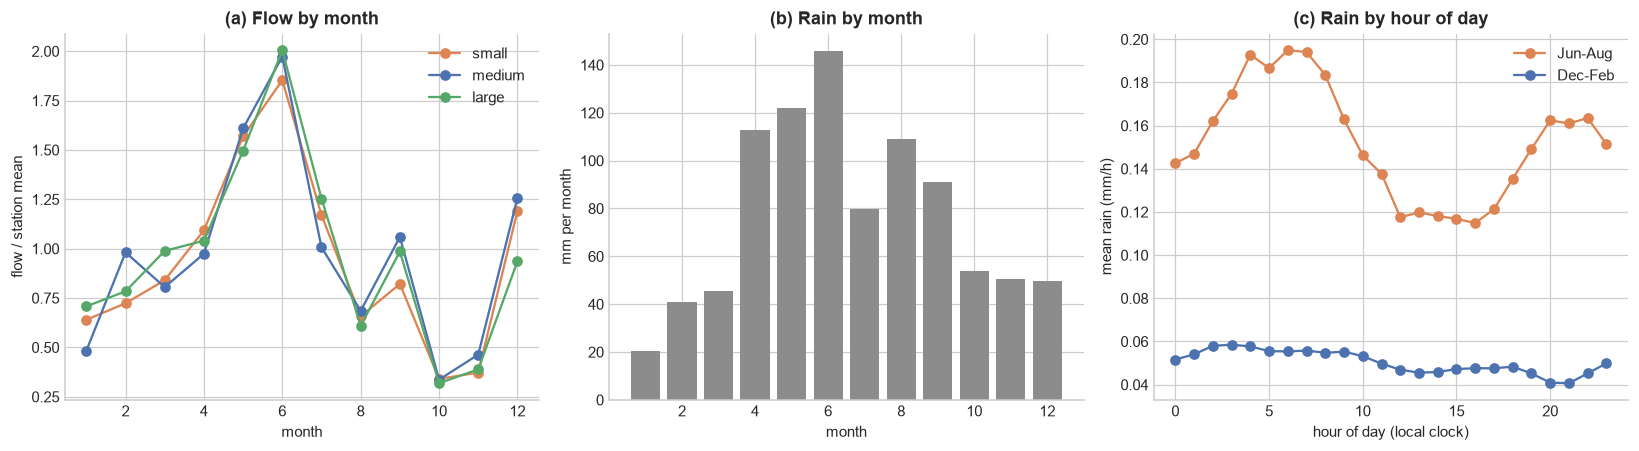

Median-station flow peaks in month 6; rain peaks in month 6; summer rain peaks at 06:00 local time.
Summer rain is 1.7x stronger at its daily peak (06:00) than at its daily low (16:00); winter ratio 1.4x.


In [6]:
months = time.month.to_numpy()[:ntr]
Qn = Qtr / np.nanmean(Qtr, axis=1, keepdims=True)           # each station divided by its own mean
mon_flow = np.array([[np.nanmean(Qn[i, months == m]) for m in range(1, 13)] for i in range(len(stations))])
rain_state = np.nanmean(P[:, :ntr], axis=0)                  # statewide mean rain each hour
mon_rain = np.array([np.nanmean(rain_state[months == m]) * 730 for m in range(1, 13)])   # mm per month (approx)
hours = time.hour.to_numpy()[:ntr]
summer = np.isin(months, [6, 7, 8]); winter = np.isin(months, [12, 1, 2])
diur_s = np.array([np.nanmean(rain_state[summer & (hours == h)]) for h in range(24)])
diur_w = np.array([np.nanmean(rain_state[winter & (hours == h)]) for h in range(24)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for g, c in GROUP_COL.items():
    axes[0].plot(range(1, 13), np.nanmedian(mon_flow[(size_group == g).to_numpy()], axis=0), color=c, marker="o", label=g)
axes[0].set_xlabel("month"); axes[0].set_ylabel("flow / station mean"); axes[0].set_title("(a) Flow by month"); axes[0].legend()
axes[1].bar(range(1, 13), mon_rain, color=GREY); axes[1].set_xlabel("month"); axes[1].set_ylabel("mm per month"); axes[1].set_title("(b) Rain by month")
axes[2].plot(range(24), diur_s, color=ORANGE, marker="o", label="Jun-Aug"); axes[2].plot(range(24), diur_w, color=BLUE, marker="o", label="Dec-Feb")
axes[2].set_xlabel("hour of day (local clock)"); axes[2].set_ylabel("mean rain (mm/h)"); axes[2].set_title("(c) Rain by hour of day"); axes[2].legend()
savefig("11_seasonal_and_diurnal.png")

wet_m = int(np.argmax(np.nanmedian(mon_flow, axis=0))) + 1
rain_m = int(np.argmax(mon_rain)) + 1
peak_h = int(np.argmax(diur_s))
print(f"Median-station flow peaks in month {wet_m}; rain peaks in month {rain_m}; summer rain peaks at {peak_h:02d}:00 local time.")
low_h = int(np.argmin(diur_s))
print(f"Summer rain is {diur_s.max() / diur_s.min():.1f}x stronger at its daily peak ({peak_h:02d}:00) than at its daily low ({low_h:02d}:00); winter ratio {diur_w.max() / diur_w.min():.1f}x.")

## 5. How long does a river remember? (ACF and PACF)

**In plain words.** The *autocorrelation function (ACF)* asks: if today's flow is high, how likely is flow *k* hours later to be high too? A river with a long memory is easy to forecast from its own past; one that forgets in hours is not. We work on log flow so floods do not dominate, and we first subtract each station's average for that calendar month, so the seasonal cycle does not fake a long memory. We summarise it as the **decorrelation time**: the first lag where the ACF falls below 0.8. (Below 0.5 almost never happens within 10 days: river memory is long, which is exactly why persistence is a strong baseline.)

The *PACF* removes indirect links (3 hours ahead is correlated with 1 hour ahead only because both are correlated with 2). Where the PACF dies out tells you how many recent hours carry *new* information. Expect: only the last few hours matter for the river's own memory, while longer windows are needed for rain and upstream signals.

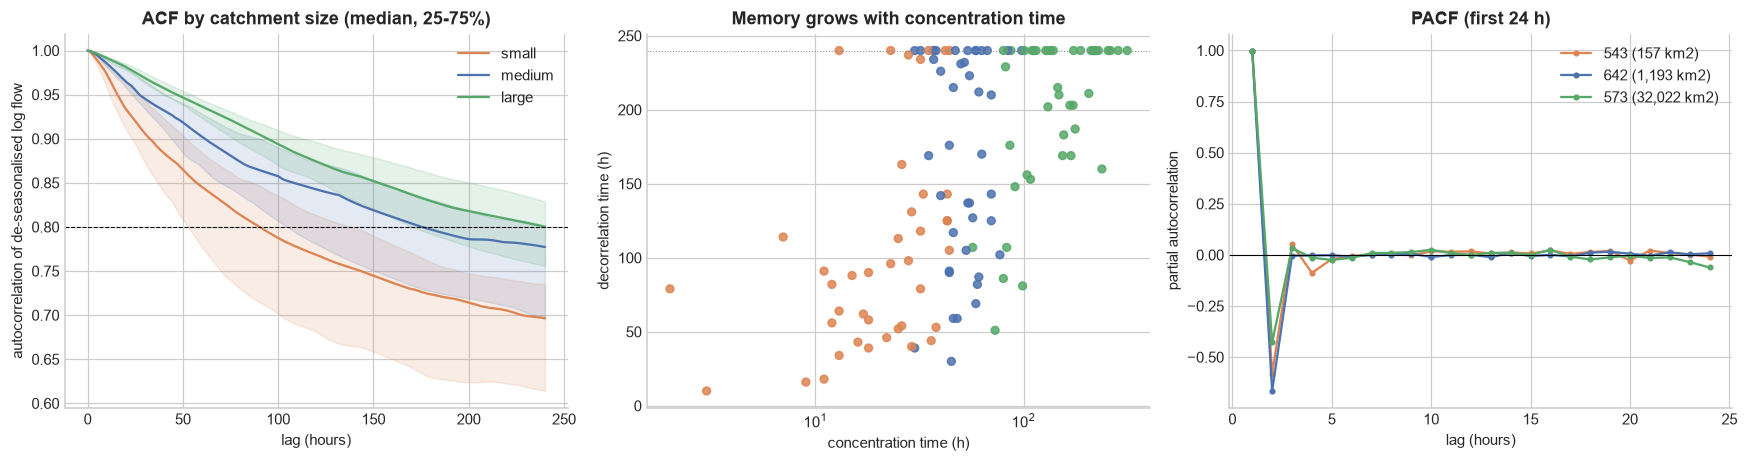

Decorrelation time (ACF < 0.8): median 169 h (range 10 to 240 h, capped at 240); Spearman with concentration time +0.55
121 of 125 stations never drop below ACF 0.5 within 240 h; 39 never drop below 0.8.
area
small      90.5
medium    176.0
large     234.5


In [7]:
MAXLAG = 240
XL = np.array([np.log(Qtr[i] + 0.01 * np.nanmean(Qtr[i])) for i in range(len(stations))])
mon0 = time.month.to_numpy()[:ntr] - 1
for i in range(len(stations)):                                   # remove each station's monthly climatology (training years)
    clim = np.array([np.nanmean(XL[i][mon0 == m]) if np.isfinite(XL[i][mon0 == m]).any() else 0.0 for m in range(12)])
    XL[i] = XL[i] - clim[mon0]
ACF = np.array([[1.0] + [pair_corr(XL[i][:-k], XL[i][k:]) for k in range(1, MAXLAG + 1)] for i in range(len(stations))])
decor = pd.Series([next((k for k in range(MAXLAG + 1) if ACF[i, k] < 0.8), MAXLAG) for i in range(len(stations))], index=stations, name="decorrelation_h")
never_half = int(np.mean([(ACF[i] >= 0.5).all() for i in range(len(stations))]) * len(stations))

def pacf_from_acf(r, nlags):
    phi = np.zeros((nlags + 1, nlags + 1)); pac = np.zeros(nlags + 1); pac[0] = 1; phi[1, 1] = pac[1] = r[1]
    for k in range(2, nlags + 1):
        phi[k, k] = (r[k] - np.sum(phi[k - 1, 1:k] * r[k - 1:0:-1])) / (1 - np.sum(phi[k - 1, 1:k] * r[1:k]))
        pac[k] = phi[k, k]
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, k - 1:0:-1]
    return pac

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for g, c in GROUP_COL.items():
    m = (size_group == g).to_numpy()
    lo, md_, hi = np.nanpercentile(ACF[m], [25, 50, 75], axis=0)
    axes[0].plot(range(MAXLAG + 1), md_, color=c, label=g); axes[0].fill_between(range(MAXLAG + 1), lo, hi, color=c, alpha=0.15)
axes[0].axhline(0.8, color="black", lw=0.7, ls="--"); axes[0].set_xlabel("lag (hours)"); axes[0].set_ylabel("autocorrelation of de-seasonalised log flow")
axes[0].set_title("ACF by catchment size (median, 25-75%)"); axes[0].legend()
axes[1].scatter(tt, decor, c=[GROUP_COL[g] for g in size_group], s=26, alpha=0.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("concentration time (h)"); axes[1].set_ylabel("decorrelation time (h)")
axes[1].set_title("Memory grows with concentration time"); axes[1].axhline(MAXLAG, color=GREY, lw=0.7, ls=":")
NL = 24
for s, c in zip([pick[0], pick[1], pick[3]], [ORANGE, BLUE, GREEN]):
    axes[2].plot(range(1, NL + 1), pacf_from_acf(ACF[idx[s]], NL)[1:], color=c, marker="o", ms=3, label=f"{s} ({area[idx[s]]:,.0f} km2)")
axes[2].axhline(0, color="black", lw=0.7); axes[2].set_xlabel("lag (hours)"); axes[2].set_ylabel("partial autocorrelation"); axes[2].set_title("PACF (first 24 h)"); axes[2].legend()
savefig("12_acf_pacf.png")

rho_dec = stats.spearmanr(tt, decor)[0]
print(f"Decorrelation time (ACF < 0.8): median {decor.median():.0f} h (range {decor.min():.0f} to {decor.max():.0f} h, capped at {MAXLAG}); Spearman with concentration time {rho_dec:+.2f}")
print(f"{never_half} of {len(stations)} stations never drop below ACF 0.5 within {MAXLAG} h; {(decor >= MAXLAG).sum()} never drop below 0.8.")
print(decor.groupby(size_group, observed=True).median().rename("median decorrelation (h)").to_string())

## 6. How long after rain does the river react?

**In plain words.** For every station we slide the rain series forward in time and find the delay at which it lines up best with the river *rising* (the hour-to-hour change in flow). That delay is the **rain-to-rise lag**. It is measured on the corrected local-time rain, so it can no longer be negative. We compare it with the *concentration time* shipped with the dataset: they measure related things, so they should move together.

This sets the minimum length of rain history the model must see, and tells us how much warning a rain *forecast* buys.

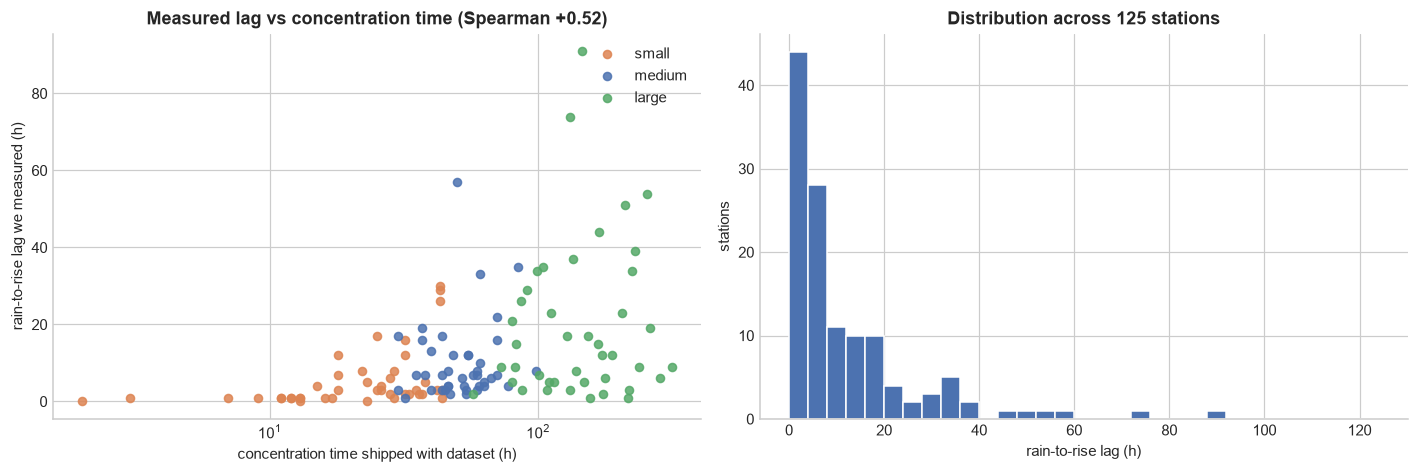

Rain-to-rise lag: median 6 h, 90th percentile 32 h, max 91 h (0 stations at the 120 h edge of the search window)
Ratio lag / concentration time: median 0.11 (the river rises fastest well before the concentration time, which is the time to the *whole catchment* contributing)
Concentration time itself: median 53 h, 90th percentile 176 h, max 315 h
Stations with peak correlation < 0.05 (weak signal): 0


In [8]:
LAGS_RF = np.arange(0, 121)
rf = []
for i, s in enumerate(stations):
    x = P[i, :ntr]
    y = np.r_[np.nan, np.diff(Qm[i, :ntr])]
    c = np.array([lag_corr(x, y, k) for k in LAGS_RF])
    j = int(np.nanargmax(c)) if np.isfinite(c).any() else 0
    rf.append((s, LAGS_RF[j], c[j]))
rf = pd.DataFrame(rf, columns=["station", "rain_to_rise_h", "peak_corr"]).set_index("station")

rho_rf = stats.spearmanr(tt, rf["rain_to_rise_h"])[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for g, c in GROUP_COL.items():
    m = (size_group == g).to_numpy()
    axes[0].scatter(tt[m], rf["rain_to_rise_h"].to_numpy()[m], color=c, s=28, alpha=0.85, label=g)
axes[0].set_xscale("log"); axes[0].set_xlabel("concentration time shipped with dataset (h)"); axes[0].set_ylabel("rain-to-rise lag we measured (h)")
axes[0].set_title(f"Measured lag vs concentration time (Spearman {rho_rf:+.2f})"); axes[0].legend()
axes[1].hist(rf["rain_to_rise_h"], bins=np.arange(0, 125, 4), color=BLUE, edgecolor="white")
axes[1].set_xlabel("rain-to-rise lag (h)"); axes[1].set_ylabel("stations"); axes[1].set_title("Distribution across 125 stations")
savefig("13_rain_to_rise_lag_vs_concentration_time.png")

at_edge = (rf["rain_to_rise_h"] >= LAGS_RF[-1]).sum()
print(f"Rain-to-rise lag: median {rf.rain_to_rise_h.median():.0f} h, 90th percentile {rf.rain_to_rise_h.quantile(0.9):.0f} h, max {rf.rain_to_rise_h.max():.0f} h "
      f"({at_edge} stations at the {LAGS_RF[-1]} h edge of the search window)")
print(f"Ratio lag / concentration time: median {np.nanmedian(rf.rain_to_rise_h / static.travel_time):.2f} "
      f"(the river rises fastest well before the concentration time, which is the time to the *whole catchment* contributing)")
print(f"Concentration time itself: median {np.median(tt):.0f} h, 90th percentile {np.percentile(tt, 90):.0f} h, max {tt.max():.0f} h")
print(f"Stations with peak correlation < 0.05 (weak signal): {(rf.peak_corr < 0.05).sum()}")

## 7. How long does a flood wave take to travel downstream?

**In plain words.** 63 gauges have one or two gauges upstream. A flood passing the upstream gauge arrives at the downstream gauge some hours later. That delay is free warning time, and it is the strongest short-range predictor of downstream flow. For each upstream -> downstream pair we find the delay at which their **3-hour rises** line up best (training years only). We also check that the arrows in `catchment_relationship.csv` really point downstream: the downstream catchment should be larger.

**Why it matters.** The upstream feature in the model should be lagged by the *measured* travel time, not guessed.

**Warning, added after looking at the result.** This hour-to-hour correlation method is only trustworthy for close, similar-sized pairs. When the downstream river is far bigger, both gauges can rise at the same moment simply because the same storm hit both, which shows up as a fake lag near zero. Section 8b therefore re-measures the travel time from actual flood peaks, which is more physical. Treat the numbers below as the rough first pass.

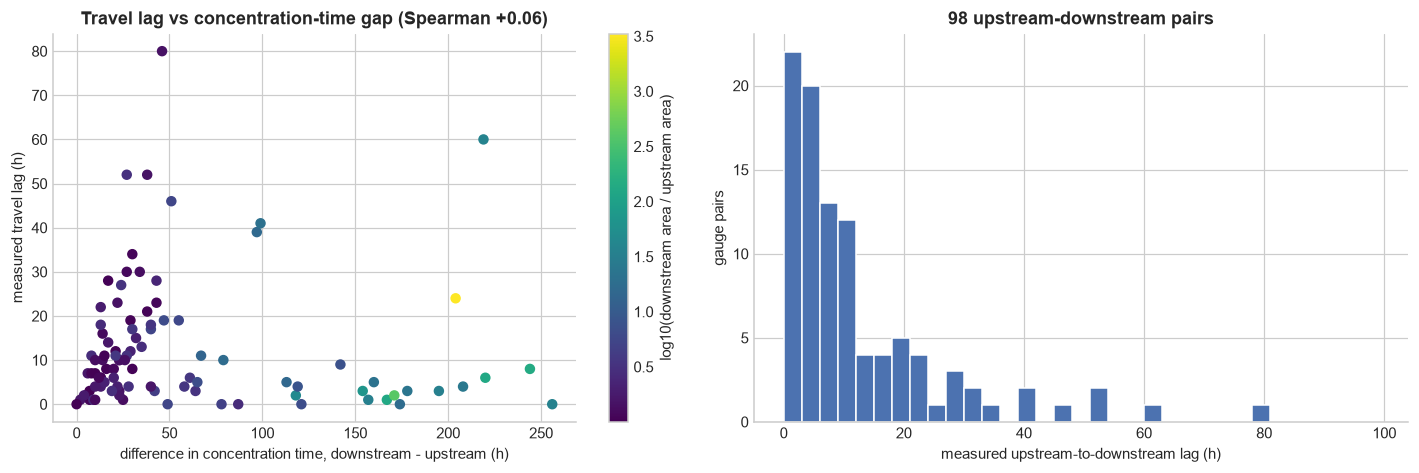

98 pairs. Downstream catchment is larger in 100% of pairs (edge direction check; should be ~100%).
Travel lag: median 7 h, range 0 to 80 h; pairs with lag 0: 7; at the 96 h window edge: 0
Peak correlation of 3-h rises: median 0.44


In [9]:
def diff3(q):
    d = np.full_like(q, np.nan); d[3:] = q[3:] - q[:-3]; return d

LAGS_UP = np.arange(0, 97)
erows = []
for _, r in rel.iterrows():
    u, d = r["upstream_id"], r["station_id"]
    if u not in idx or d not in idx:
        continue
    x, y = diff3(Qm[idx[u], :ntr]), diff3(Qm[idx[d], :ntr])
    c = np.array([lag_corr(x, y, k) for k in LAGS_UP])
    j = int(np.nanargmax(c)) if np.isfinite(c).any() else 0
    erows.append(dict(upstream=u, downstream=d, best_lag_h=LAGS_UP[j], peak_corr=c[j],
                      tt_diff_h=tt[idx[d]] - tt[idx[u]], area_ratio=area[idx[d]] / area[idx[u]]))
edges = pd.DataFrame(erows)

dir_ok = float((edges["area_ratio"] > 1).mean())
rho_up = stats.spearmanr(edges["tt_diff_h"], edges["best_lag_h"])[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
sc = axes[0].scatter(edges["tt_diff_h"], edges["best_lag_h"], c=np.log10(edges["area_ratio"]), cmap="viridis", s=34)
plt.colorbar(sc, ax=axes[0], label="log10(downstream area / upstream area)")
axes[0].set_xlabel("difference in concentration time, downstream - upstream (h)"); axes[0].set_ylabel("measured travel lag (h)")
axes[0].set_title(f"Travel lag vs concentration-time gap (Spearman {rho_up:+.2f})")
axes[1].hist(edges["best_lag_h"], bins=np.arange(0, 100, 3), color=BLUE, edgecolor="white")
axes[1].set_xlabel("measured upstream-to-downstream lag (h)"); axes[1].set_ylabel("gauge pairs"); axes[1].set_title(f"{len(edges)} upstream-downstream pairs")
savefig("14_upstream_downstream_lag.png")

print(f"{len(edges)} pairs. Downstream catchment is larger in {dir_ok:.0%} of pairs (edge direction check; should be ~100%).")
print(f"Travel lag: median {edges.best_lag_h.median():.0f} h, range {edges.best_lag_h.min()} to {edges.best_lag_h.max()} h; "
      f"pairs with lag 0: {(edges.best_lag_h == 0).sum()}; at the {LAGS_UP[-1]} h window edge: {(edges.best_lag_h >= LAGS_UP[-1]).sum()}")
print(f"Peak correlation of 3-h rises: median {edges.peak_corr.median():.2f}")
edges.to_csv(PROC / "upstream_lags.csv", index=False)

## 8. Floods: what counts as one, and how fast do they build?

**In plain words.** A "flood" here means flow above that station's own **95th percentile**, computed on the **training years only** (the validation and test years never influence the threshold). Neighbouring bursts less than 24 hours apart are merged into one event, because one storm can wobble above and below the line. For each event we record the peak and the **rise time**: hours from first crossing the threshold to the peak. That rise time is the window a gate operator has to act once the river is already "high".

We also keep the 99th percentile as a "major flood" line. Events are counted in the training and validation years only; the test year stays untouched.

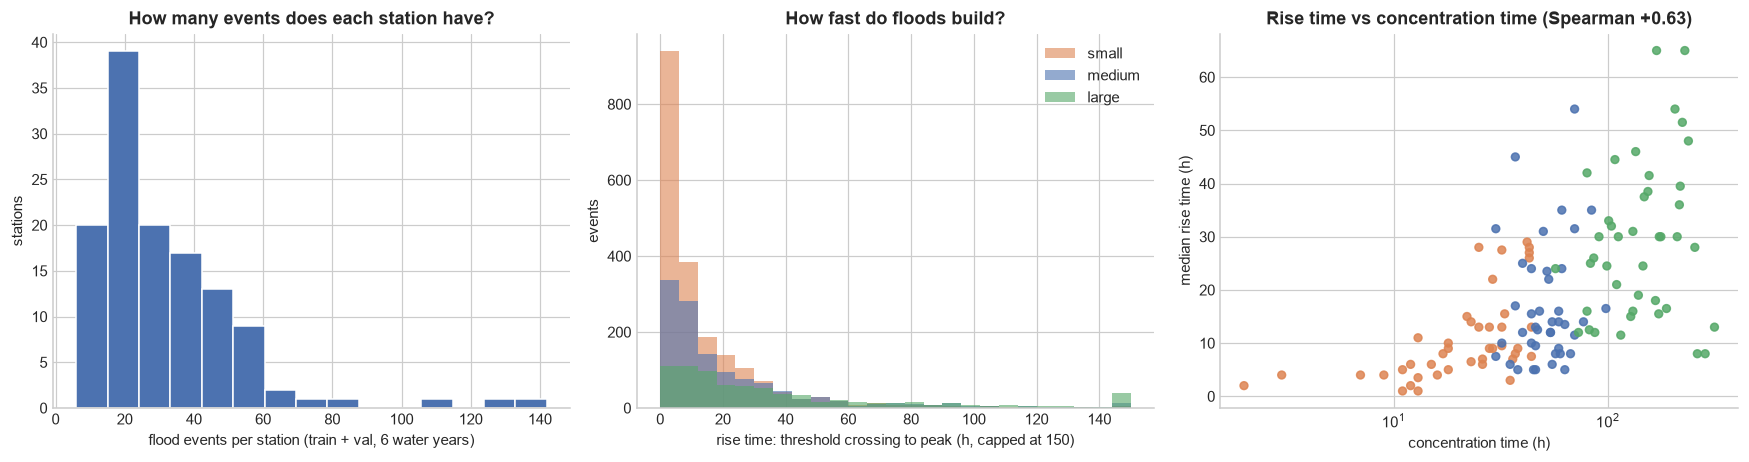

3,975 flood events (train 3382, val 593); 1283 are above the Q99 line.
Events per station: median 25, min 6, max 142; stations with fewer than 5 events: 0
Rise time (threshold crossing to peak): median 10 h, 25th pct 3 h, 75th pct 26 h
station
large     23.5
medium    11.0
small      6.0

Five largest events relative to their own Q99 (candidates for the gate replay later):


,station,peak_time,peak_q,peak_over_q99,rise_h,split
717,541,2016-08-12 06:00:00,143.00,35.68,7,train
1103,553,2014-06-30 20:00:00,19.40,33.33,47,train
1088,553,2013-04-17 13:00:00,19.14,32.88,3,train
697,541,2014-07-12 21:00:00,105.69,26.37,15,train
1105,553,2014-07-12 20:00:00,14.85,25.50,15,train


In [10]:
q50 = np.nanmedian(Qm[:, :ntr], axis=1)
q95 = np.nanpercentile(Qm[:, :ntr], 95, axis=1)
q99 = np.nanpercentile(Qm[:, :ntr], 99, axis=1)
thr = pd.DataFrame({"q50": q50, "q95": q95, "q99": q99}, index=stations)
thr.index.name = "station"
thr.to_csv(PROC / "flood_thresholds_train.csv")

MERGE_GAP = 24
avail = split != "test"
ev = []
for i, s in enumerate(stations):
    q = np.where(avail, Qm[i], np.nan)
    m = (np.nan_to_num(q, nan=-1.0) > q95[i]).astype(np.int8)
    d = np.diff(np.r_[0, m, 0])
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    merged = []
    for a, b in zip(starts, ends):
        if merged and a - merged[-1][1] < MERGE_GAP:
            merged[-1][1] = b
        else:
            merged.append([a, b])
    for a, b in merged:
        seg = q[a:b]
        k = int(np.nanargmax(seg)); pk = a + k
        ev.append(dict(station=s, start=time[a], peak_time=time[pk], end=time[b - 1], peak_q=seg[k], rise_h=k, duration_h=b - a,
                       peak_over_q99=seg[k] / q99[i], split=split[pk], major=bool(seg[k] > q99[i])))
events = pd.DataFrame(ev)
events.to_csv(PROC / "flood_events_trainval.csv", index=False)

per_station = events.groupby("station").size().reindex(stations).fillna(0)
rise_tt = stats.spearmanr(tt, events.groupby("station")["rise_h"].median().reindex(stations).fillna(0))[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].hist(per_station, bins=15, color=BLUE, edgecolor="white"); axes[0].set_xlabel("flood events per station (train + val, 6 water years)"); axes[0].set_ylabel("stations")
axes[0].set_title("How many events does each station have?")
for g, c in GROUP_COL.items():
    m = events["station"].map(size_group.to_dict()) == g
    axes[1].hist(events.loc[m, "rise_h"].clip(upper=150), bins=np.arange(0, 155, 6), color=c, alpha=0.6, label=g)
axes[1].set_xlabel("rise time: threshold crossing to peak (h, capped at 150)"); axes[1].set_ylabel("events"); axes[1].set_title("How fast do floods build?"); axes[1].legend()
med_rise = events.groupby("station")["rise_h"].median()
axes[2].scatter(tt[[idx[s] for s in med_rise.index]], med_rise.values, c=[GROUP_COL[size_group[s]] for s in med_rise.index], s=26, alpha=0.85)
axes[2].set_xscale("log"); axes[2].set_xlabel("concentration time (h)"); axes[2].set_ylabel("median rise time (h)"); axes[2].set_title(f"Rise time vs concentration time (Spearman {rise_tt:+.2f})")
savefig("15_flood_events.png")

print(f"{len(events):,} flood events (train {int((events.split == 'train').sum())}, val {int((events.split == 'val').sum())}); {int(events.major.sum())} are above the Q99 line.")
print(f"Events per station: median {per_station.median():.0f}, min {int(per_station.min())}, max {int(per_station.max())}; stations with fewer than 5 events: {(per_station < 5).sum()}")
print(f"Rise time (threshold crossing to peak): median {events.rise_h.median():.0f} h, 25th pct {events.rise_h.quantile(.25):.0f} h, 75th pct {events.rise_h.quantile(.75):.0f} h")
print(events.groupby(events["station"].map(size_group.to_dict()), observed=True)["rise_h"].median().rename("median rise time (h) by size").to_string())
print("\nFive largest events relative to their own Q99 (candidates for the gate replay later):")
display(events.sort_values("peak_over_q99", ascending=False).head(5)[["station", "peak_time", "peak_q", "peak_over_q99", "rise_h", "split"]].round(2))

## 8b. Travel time again, this time from flood peaks

**In plain words.** Instead of correlating every wiggle, follow actual floods. For each flood peak at a downstream gauge (training years only, from section 8), look at the 120 hours before it and find when the **upstream gauge peaked**. The gap between those two peaks is that flood's travel time. We take the median over all of a pair's floods. This avoids the "same storm hit both gauges" trap, because we only compare *peaks*, not every fluctuation. Where the spread between floods is wide, the lag is genuinely uncertain, and we keep that spread (25th-75th percentile) rather than hiding it. Lags stuck at the 120 h window edge are not reliable.

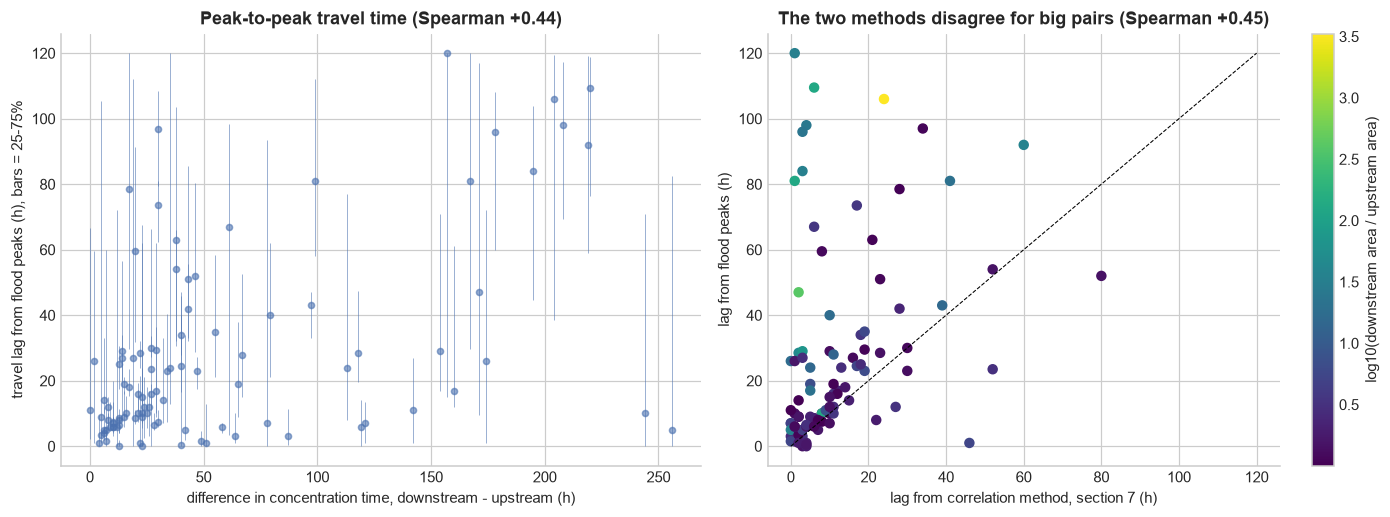

Peak-to-peak travel lag: median 16 h, 25th-75th pct of pair medians 7-30 h, max 120 h; 1 pairs stuck at the 120 h window edge
Median spread between a pair's floods (75th - 25th pct): 23 h
Agreement with concentration-time gap: peak method +0.44 vs correlation method +0.06


In [11]:
W_UP = 120
events_tr = events[events["split"] == "train"]
rows = []
for j, r in edges.iterrows():
    u = idx[r["upstream"]]
    pk = time.get_indexer(events_tr.loc[events_tr["station"] == r["downstream"], "peak_time"])
    lags = []
    for k in pk:
        if k < W_UP:
            continue
        w = Qm[u, k - W_UP:k + 1]
        if np.isnan(w).mean() > 0.3:
            continue
        lags.append(W_UP - int(np.nanargmax(w)))
    rows.append((len(lags), np.median(lags) if lags else np.nan,
                 np.percentile(lags, 25) if lags else np.nan, np.percentile(lags, 75) if lags else np.nan))
edges[["n_events", "event_lag_h", "event_lag_q25", "event_lag_q75"]] = pd.DataFrame(rows, index=edges.index)

ok_e = edges["n_events"] >= 5
rho_up_ev = stats.spearmanr(edges.loc[ok_e, "tt_diff_h"], edges.loc[ok_e, "event_lag_h"])[0]
rho_methods = stats.spearmanr(edges.loc[ok_e, "event_lag_h"], edges.loc[ok_e, "best_lag_h"])[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
e = edges[ok_e]
axes[0].errorbar(e["tt_diff_h"], e["event_lag_h"], yerr=[e["event_lag_h"] - e["event_lag_q25"], e["event_lag_q75"] - e["event_lag_h"]],
                 fmt="o", color=BLUE, ecolor=BLUE, elinewidth=0.6, alpha=0.6, ms=4)
axes[0].set_xlabel("difference in concentration time, downstream - upstream (h)"); axes[0].set_ylabel("travel lag from flood peaks (h), bars = 25-75%")
axes[0].set_title(f"Peak-to-peak travel time (Spearman {rho_up_ev:+.2f})")
sc = axes[1].scatter(e["best_lag_h"], e["event_lag_h"], c=np.log10(e["area_ratio"]), cmap="viridis", s=34)
plt.colorbar(sc, ax=axes[1], label="log10(downstream area / upstream area)")
axes[1].plot([0, 120], [0, 120], color="black", lw=0.7, ls="--")
axes[1].set_xlabel("lag from correlation method, section 7 (h)"); axes[1].set_ylabel("lag from flood peaks (h)")
axes[1].set_title(f"The two methods disagree for big pairs (Spearman {rho_methods:+.2f})")
savefig("14b_upstream_travel_from_peaks.png")

print(f"Peak-to-peak travel lag: median {e.event_lag_h.median():.0f} h, 25th-75th pct of pair medians {e.event_lag_h.quantile(.25):.0f}-{e.event_lag_h.quantile(.75):.0f} h, "
      f"max {e.event_lag_h.max():.0f} h; {int((e.event_lag_h >= W_UP - 1).sum())} pairs stuck at the {W_UP} h window edge")
print(f"Median spread between a pair's floods (75th - 25th pct): {(e.event_lag_q75 - e.event_lag_q25).median():.0f} h")
print(f"Agreement with concentration-time gap: peak method {rho_up_ev:+.2f} vs correlation method {rho_up:+.2f}")
edges.to_csv(PROC / "upstream_lags.csv", index=False)

## 9. Group the catchments by how they behave

**In plain words.** 125 catchments are too many to discuss one by one, and reporting one pooled score hides everything. We group them with *k-means clustering* on traits that describe behaviour: size, response time, slope, soil mix, flashiness, and how extreme the flood tail is. The number of groups (3 to 5) is picked by the **silhouette score** (how cleanly the groups separate; above about 0.5 is a clear structure, below about 0.35 is weak). Scores here are low, which is itself a finding: the catchments form a *continuum*, not separate species. So the **size terciles are the primary reporting groups** and the clusters are a secondary view. Neither is used to build separate models.

stations with a missing feature value: 0


,2,3,4,5
silhouette,0.318,0.238,0.244,0.262


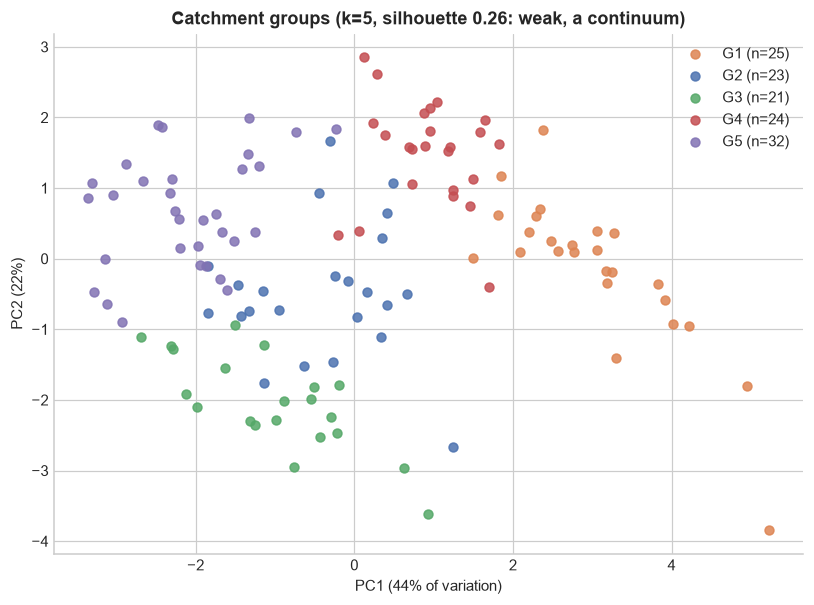

,n,area_km2,tc_h,flashiness,q99_over_q50,missing_%
cluster,,,,,,
G1,25,309.0,18.0,0.04,23.98,17.02
G2,23,1271.0,44.0,0.02,15.60,16.87
G3,21,1456.0,40.0,0.01,21.04,16.52
G4,24,1910.0,54.5,0.02,15.49,15.19
G5,32,13763.5,168.0,0.01,10.73,15.27


In [12]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

feat = pd.DataFrame({
    "log_area": np.log10(static["area"]), "log_tc": np.log10(static["travel_time"]), "log_slope": np.log10(static["slope"]),
    "loam": static["loam"], "silt": static["silt"], "sandy_clay_loam": static["sandy_clay_loam"], "silty_clay_loam": static["silty_clay_loam"],
    "log_flashiness": np.log10(rb), "log_q99_over_q50": np.log10(thr["q99"] / thr["q50"]),
})
feat = feat.replace([np.inf, -np.inf], np.nan)
print("stations with a missing feature value:", int(feat.isna().any(axis=1).sum()))
feat = feat.fillna(feat.median())
Z = StandardScaler().fit_transform(feat)

sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 6)}
display(pd.Series(sil, name="silhouette").round(3).to_frame().T)
K = max((k for k in sil if k >= 3), key=sil.get)
labels = KMeans(K, n_init=20, random_state=SEED).fit_predict(Z)
pcs = PCA(2, random_state=SEED).fit(Z); XY = pcs.transform(Z)

# name clusters by their median area so the labels are readable, smallest first
order = pd.Series(area).groupby(labels).median().sort_values().index.tolist()
rename = {c: f"G{j + 1}" for j, c in enumerate(order)}
cluster = pd.Series([rename[c] for c in labels], index=stations, name="cluster")

fig, ax = plt.subplots(figsize=(7.5, 5.6))
palette = [ORANGE, BLUE, GREEN, RED, PURPLE, GREY]
for j, g in enumerate(sorted(cluster.unique())):
    m = (cluster == g).to_numpy()
    ax.scatter(XY[m, 0], XY[m, 1], color=palette[j], s=34, alpha=0.85, label=f"{g} (n={m.sum()})")
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variation)"); ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.set_title(f"Catchment groups (k={K}, silhouette {sil[K]:.2f}: weak, a continuum)"); ax.legend()
savefig("16_catchment_clusters.png")

summ = pd.DataFrame({"area_km2": static["area"], "tc_h": static["travel_time"], "flashiness": rb, "q99_over_q50": thr["q99"] / thr["q50"],
                     "missing_%": static["flow_missing_pct"]}).groupby(cluster).median().round(2)
summ.insert(0, "n", cluster.value_counts().sort_index())
display(summ)

groups = pd.DataFrame({"size_group": size_group.astype(str), "cluster": cluster, "area": static["area"], "travel_time": static["travel_time"],
                       "flashiness": rb, "decorrelation_h": decor, "rain_to_rise_h": rf["rain_to_rise_h"]})
groups.index.name = "station"
groups.to_csv(PROC / "station_groups.csv")

## 10. The floor to beat: persistence skill by lead time

**In plain words.** The laziest forecast is *persistence*: "the flow in *h* hours will be what it is now." It costs nothing, so every real model must beat it. We measure how good persistence is with **NSE** (1 is perfect, 0 means no better than always guessing the average, below 0 is worse than that). It is measured on the **validation year only**, per station, at the lead times we care about.

**Two ways to average, and why it matters.** Pooling all stations into one NSE lets the huge rivers (large, slow, easy to persist) swamp the creeks, which flatters persistence. A *per-station* NSE gives each river an equal vote. We report both so the gap is visible, and use the per-station numbers as the honest benchmark.

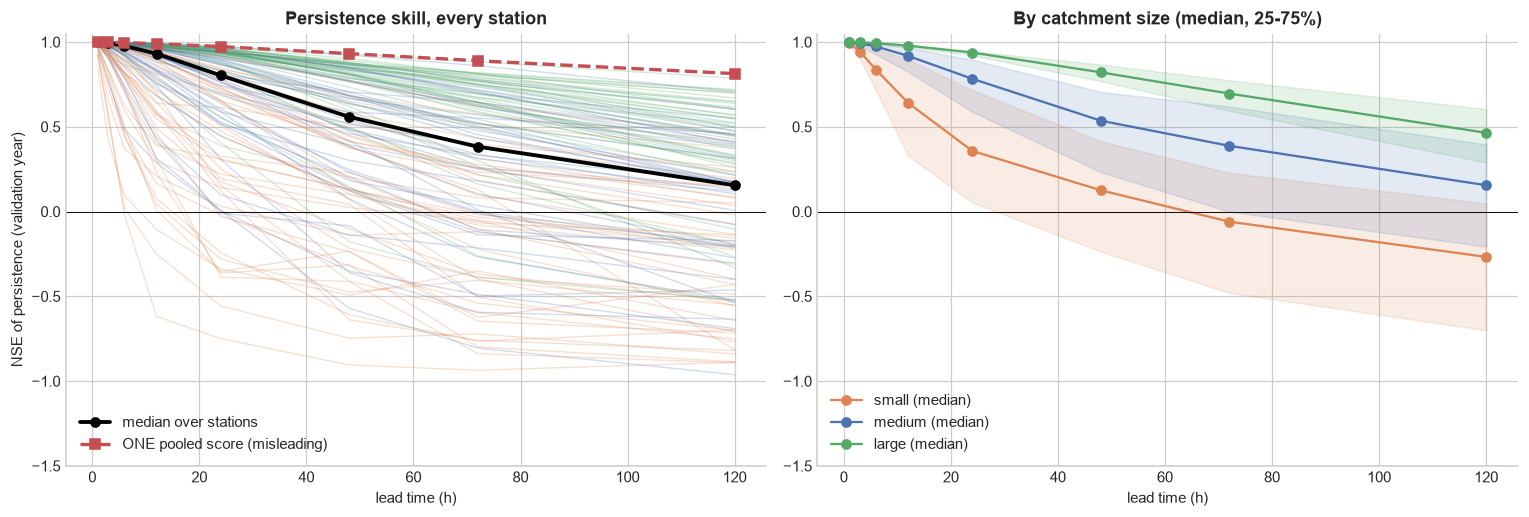

,1,3,6,12,24,48,72,120
median NSE (per station),1.0,0.99,0.98,0.93,0.80,0.56,0.38,0.16
pooled NSE (one score),1.0,1.00,1.00,0.99,0.97,0.93,0.89,0.81
stations with NSE < 0,0.0,0.00,1.00,3.00,11.00,21.00,38.00,51.00


lead (h),1,3,6,12,24,48,72,120
area,,,,,,,,
small,0.99,0.94,0.84,0.64,0.36,0.13,-0.06,-0.27
medium,1.00,0.99,0.97,0.92,0.78,0.54,0.39,0.16
large,1.00,1.00,0.99,0.98,0.94,0.82,0.70,0.46


In [13]:
H_LIST = [1, 3, 6, 12, 24, 48, 72, 120]
v0, v1 = ntr, ntr + nva                      # validation year only; the test year is never used
Qv = Qm[:, v0:v1]

def nse(y, yhat):
    m = ~(np.isnan(y) | np.isnan(yhat))
    if m.sum() < 500: return np.nan
    y, yhat = y[m], yhat[m]
    d = ((y - y.mean()) ** 2).sum()
    return 1 - ((y - yhat) ** 2).sum() / d if d > 0 else np.nan

per = {}; pooled = {}
for h in H_LIST:
    obs, pred = Qv[:, h:], Qv[:, :-h]            # forecast made at t, verified at t+h, both inside the validation year
    per[h] = [nse(obs[i], pred[i]) for i in range(len(stations))]
    pooled[h] = nse(obs.ravel(), pred.ravel())
persist = pd.DataFrame(per, index=stations); persist.columns.name = "lead (h)"
persist.index.name = "station"
persist.to_csv(PROC / "persistence_skill_val.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, s in enumerate(stations):
    axes[0].plot(H_LIST, persist.loc[s].values, color=GROUP_COL[size_group.iloc[i]], alpha=0.25, lw=0.9)
axes[0].plot(H_LIST, persist.median().values, color="black", lw=2.5, marker="o", label="median over stations")
axes[0].plot(H_LIST, [pooled[h] for h in H_LIST], color=RED, lw=2.2, ls="--", marker="s", label="ONE pooled score (misleading)")
axes[0].set_ylim(-1.5, 1.05); axes[0].axhline(0, color="black", lw=0.6)
axes[0].set_xlabel("lead time (h)"); axes[0].set_ylabel("NSE of persistence (validation year)"); axes[0].set_title("Persistence skill, every station"); axes[0].legend()
for g, c in GROUP_COL.items():
    sub = persist[(size_group == g).to_numpy()]
    axes[1].plot(H_LIST, sub.median().values, color=c, marker="o", label=f"{g} (median)")
    axes[1].fill_between(H_LIST, sub.quantile(0.25).values, sub.quantile(0.75).values, color=c, alpha=0.15)
axes[1].set_ylim(-1.5, 1.05); axes[1].axhline(0, color="black", lw=0.6)
axes[1].set_xlabel("lead time (h)"); axes[1].set_title("By catchment size (median, 25-75%)"); axes[1].legend()
savefig("17_persistence_skill.png")

tbl = pd.DataFrame({"median NSE (per station)": persist.median(), "pooled NSE (one score)": pd.Series(pooled),
                    "stations with NSE < 0": (persist < 0).sum()}).round(2)
display(tbl.T)
display(persist.groupby(size_group, observed=True).median().round(2))

## 11. Splits and the leakage buffer

**In plain words.** The chronological split is fixed: **train** Oct 2011 - Sep 2016, **validation** Oct 2016 - Sep 2017, **test** Oct 2017 - Sep 2018. A forecasting sample looks back *L* hours (the input window) and forward *H* hours (the targets). If that whole window straddles a boundary, the model has quietly seen the next period. The rule is therefore: **every sample must sit entirely inside one split**. That wastes the first *L + H* hours of each split as a buffer. We fix it now, in one file, so every notebook uses the same split.

Here *L* = 336 h (two weeks of history, the longest we plan to try) and *H* = 120 h (the paper's 5-day horizon).

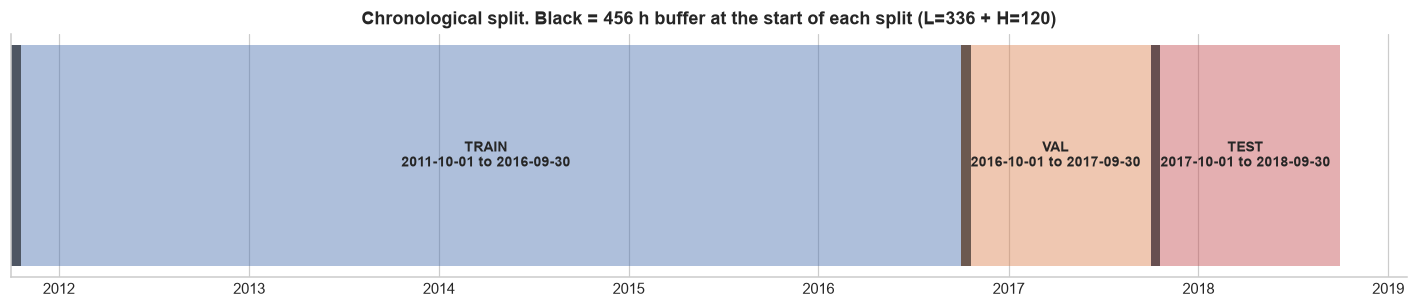

Missing flow in Dec-Mar by split (%): {'train': 49.0, 'val': 30.5, 'test': 3.4} | other months: {'train': 3.9, 'val': 0.3, 'test': 0.1}
Valid forecast origins per split: {'train': 43392, 'val': 8304, 'test': 8304}
Median % of hours with missing flow per station (counting missing data is fine; no test values are inspected):
train    19.7
val      10.6
test      0.2
saved processed/splits.json


In [14]:
L_MAX, H_MAX = 336, 120
BUFFER = L_MAX + H_MAX
bounds = {s: (int(np.where(split == s)[0][0]), int(np.where(split == s)[0][-1])) for s in ("train", "val", "test")}
spec = {"clock": "Iowa local time; rain column to use is precip_local", "lookback_max_h": L_MAX, "horizon_max_h": H_MAX, "buffer_h": BUFFER,
        "rule": "origin t is valid for a split only if t-L >= split_start and t+H <= split_end (the whole window inside one split)", "splits": {}}
for s, (a, b) in bounds.items():
    first, last = a + L_MAX, b - H_MAX
    spec["splits"][s] = dict(start=str(time[a]), end=str(time[b]), first_origin=str(time[first]), last_origin=str(time[last]), n_origins=int(last - first + 1))
(PROC / "splits.json").write_text(json.dumps(spec, indent=2))

fig, ax = plt.subplots(figsize=(13, 2.9))
cols = {"train": BLUE, "val": ORANGE, "test": RED}
for s, (a, b) in bounds.items():
    ax.barh(0, time[b] - time[a], left=time[a], color=cols[s], alpha=0.45, height=0.5)
    ax.barh(0, pd.Timedelta(hours=BUFFER), left=time[a], color="black", alpha=0.55, height=0.5)
    ax.text(time[a] + (time[b] - time[a]) / 2, 0, f"{s.upper()}\n{time[a].date()} to {time[b].date()}", ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_yticks([]); ax.set_title(f"Chronological split. Black = {BUFFER} h buffer at the start of each split (L={L_MAX} + H={H_MAX})")
savefig("18_splits_and_buffer.png")

miss_by_split = pd.DataFrame({s: np.isnan(Q[:, a:b + 1]).mean(axis=1) * 100 for s, (a, b) in bounds.items()}, index=stations)
wint = np.isin(time.month.to_numpy(), [12, 1, 2, 3])
miss_winter = {s: float(np.isnan(Q[:, a:b + 1][:, wint[a:b + 1]]).mean() * 100) for s, (a, b) in bounds.items()}
miss_other = {s: float(np.isnan(Q[:, a:b + 1][:, ~wint[a:b + 1]]).mean() * 100) for s, (a, b) in bounds.items()}
print("Missing flow in Dec-Mar by split (%):", {k: round(v, 1) for k, v in miss_winter.items()}, "| other months:", {k: round(v, 1) for k, v in miss_other.items()})
print("Valid forecast origins per split:", {s: v["n_origins"] for s, v in spec["splits"].items()})
print("Median % of hours with missing flow per station (counting missing data is fine; no test values are inspected):")
print(miss_by_split.median().round(1).to_string())
print("saved", PROC / "splits.json")

## 12. Findings and decisions

**In plain words.** The table that turns this notebook into design choices. Numbers are filled in from the cells above, not typed by hand.

In [15]:
f = {}
f["skew"] = f"median skewness {skew_tbl.skew_raw.median():.1f} (raw) -> {skew_tbl.skew_sqrt.median():.1f} (sqrt) -> {skew_tbl.skew_log.median():.1f} (log); Q99 is {skew_tbl.q99_over_q50.median():.0f}x the median"
f["flash"] = f"flashiness falls with area (Spearman {rho_area:+.2f}) and concentration time ({rho_tt:+.2f})"
f["memory"] = f"after removing the seasonal cycle, flow stays correlated (ACF > 0.8) for a median {decor.median():.0f} h (small {decor[size_group == 'small'].median():.0f} h, large {decor[size_group == 'large'].median():.0f} h); Spearman with concentration time {rho_dec:+.2f}"
f["rain"] = f"flow rises a median {rf.rain_to_rise_h.median():.0f} h after rain (90th pct {rf.rain_to_rise_h.quantile(.9):.0f} h; Spearman with concentration time {rho_rf:+.2f}); concentration time median {np.median(tt):.0f} h, 90th pct {np.percentile(tt, 90):.0f} h, max {tt.max():.0f} h"
f["up"] = f"{len(edges)} upstream-downstream pairs (downstream larger in {dir_ok:.0%}); flood-peak travel time median {e.event_lag_h.median():.0f} h, up to {e.event_lag_h.max():.0f} h, but spread between floods is wide (median IQR {(e.event_lag_q75 - e.event_lag_q25).median():.0f} h). Peak method tracks concentration-time gap (Spearman {rho_up_ev:+.2f}); correlation method does not ({rho_up:+.2f}) and fakes near-zero lags for big nested pairs"
f["flood"] = f"{len(events):,} Q95 events in train+val; rise time from threshold to peak median {events.rise_h.median():.0f} h; {int((per_station < 5).sum())} stations have < 5 events"
p24, p120, p1 = persist[24].median(), persist[120].median(), persist[1].median()
f["pers"] = f"persistence median per-station NSE {p1:.2f} (1 h), {persist[6].median():.2f} (6 h), {p24:.2f} (24 h), {p120:.2f} (120 h) vs pooled {pooled[24]:.2f} (24 h) and {pooled[120]:.2f} (120 h)"
f["clu"] = f"{K} clusters but silhouette only {sil[K]:.2f} (a continuum, not separate types); size terciles are the main reporting groups"
f["miss"] = f"missing flow in Dec-Mar is {miss_winter['train']:.0f}% in train, {miss_winter['val']:.0f}% in validation but only {miss_winter['test']:.0f}% in the test year"

table = [
 ("Flows are strongly right-skewed: " + f["skew"], "Train on a transformed target (sqrt or log) or an NSE-style loss; report in m3/s. Compare in an ablation."),
 ("Rivers differ in flashiness: " + f["flash"], "Report every metric per size group and per cluster, never pooled. Give the model area, concentration time and slope as static inputs."),
 ("Memory of the river's own past: " + f["memory"], "Memory is long (days to weeks), so persistence is strong and a long hindcast window is justified: test 168 h and 336 h. Long windows matter most for large rivers."),
 ("Rain-to-flow timing: " + f["rain"], "Rain history window covers at least the 90th-percentile concentration time (use 168-336 h). Short-lead forecasts for small catchments depend heavily on future rain."),
 ("Upstream travel time: " + f["up"], "Add upstream flow as a feature, but give the model SEVERAL lags per upstream gauge (a grid around the peak-method lag, e.g. 0 to 2x that lag) rather than one fixed value, because travel time varies a lot between floods. Use the peak method, not the correlation method. Re-estimate on training years only."),
 ("Floods: " + f["flood"], "Use the saved Q95/Q99 (training years) for POD/FAR/CSI and peak metrics. Rise time sets the realistic warning window for the gate."),
 ("Persistence floor: " + f["pers"], "Beat persistence per station at every lead time; report the pooled-vs-per-station gap explicitly. Skill that is only above persistence beyond ~12 h is where a model can add value."),
 ("Behaviour groups: " + f["clu"], "Report by size tercile first, cluster second. Neither builds separate models. Pick the gate-site stand-in from a mid-size downstream catchment with upstream gauges and low missing data."),
 ("Data regime shift: " + f["miss"], "Winter (ice-affected) flow is mostly absent from training but present in test, so test skill in Dec-Mar is on conditions the model barely saw, and those values may be estimated. Report test skill with and without Dec-Mar; do not hide this."),
 ("One fixed split with an L+H buffer (saved to splits.json)", "Every later notebook imports the same split. The test year is touched once, at the very end."),
]
md_ = "| Finding | Decision for modelling |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in table)
display(Markdown(md_))
print("\nFILES WRITTEN to processed/: " + ", ".join(sorted(p.name for p in PROC.iterdir() if p.name in
      {"flood_thresholds_train.csv", "flood_events_trainval.csv", "upstream_lags.csv", "station_groups.csv", "persistence_skill_val.csv", "splits.json"})))

| Finding | Decision for modelling |
|---|---|
| Flows are strongly right-skewed: median skewness 5.6 (raw) -> 1.9 (sqrt) -> 0.1 (log); Q99 is 16x the median | Train on a transformed target (sqrt or log) or an NSE-style loss; report in m3/s. Compare in an ablation. |
| Rivers differ in flashiness: flashiness falls with area (Spearman -0.85) and concentration time (-0.85) | Report every metric per size group and per cluster, never pooled. Give the model area, concentration time and slope as static inputs. |
| Memory of the river's own past: after removing the seasonal cycle, flow stays correlated (ACF > 0.8) for a median 169 h (small 90 h, large 234 h); Spearman with concentration time +0.55 | Memory is long (days to weeks), so persistence is strong and a long hindcast window is justified: test 168 h and 336 h. Long windows matter most for large rivers. |
| Rain-to-flow timing: flow rises a median 6 h after rain (90th pct 32 h; Spearman with concentration time +0.52); concentration time median 53 h, 90th pct 176 h, max 315 h | Rain history window covers at least the 90th-percentile concentration time (use 168-336 h). Short-lead forecasts for small catchments depend heavily on future rain. |
| Upstream travel time: 98 upstream-downstream pairs (downstream larger in 100%); flood-peak travel time median 16 h, up to 120 h, but spread between floods is wide (median IQR 23 h). Peak method tracks concentration-time gap (Spearman +0.44); correlation method does not (+0.06) and fakes near-zero lags for big nested pairs | Add upstream flow as a feature, but give the model SEVERAL lags per upstream gauge (a grid around the peak-method lag, e.g. 0 to 2x that lag) rather than one fixed value, because travel time varies a lot between floods. Use the peak method, not the correlation method. Re-estimate on training years only. |
| Floods: 3,975 Q95 events in train+val; rise time from threshold to peak median 10 h; 0 stations have < 5 events | Use the saved Q95/Q99 (training years) for POD/FAR/CSI and peak metrics. Rise time sets the realistic warning window for the gate. |
| Persistence floor: persistence median per-station NSE 1.00 (1 h), 0.98 (6 h), 0.80 (24 h), 0.16 (120 h) vs pooled 0.97 (24 h) and 0.81 (120 h) | Beat persistence per station at every lead time; report the pooled-vs-per-station gap explicitly. Skill that is only above persistence beyond ~12 h is where a model can add value. |
| Behaviour groups: 5 clusters but silhouette only 0.26 (a continuum, not separate types); size terciles are the main reporting groups | Report by size tercile first, cluster second. Neither builds separate models. Pick the gate-site stand-in from a mid-size downstream catchment with upstream gauges and low missing data. |
| Data regime shift: missing flow in Dec-Mar is 49% in train, 30% in validation but only 3% in the test year | Winter (ice-affected) flow is mostly absent from training but present in test, so test skill in Dec-Mar is on conditions the model barely saw, and those values may be estimated. Report test skill with and without Dec-Mar; do not hide this. |
| One fixed split with an L+H buffer (saved to splits.json) | Every later notebook imports the same split. The test year is touched once, at the very end. |


FILES WRITTEN to processed/: flood_events_trainval.csv, flood_thresholds_train.csv, persistence_skill_val.csv, splits.json, station_groups.csv, upstream_lags.csv
